In [61]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths, savgol_filter
import pandas as pd
import h5py

plt.rcParams["figure.dpi"] = 150

In [4]:
def plot_with_peaks(
    signal,
    n_bins,
    prominence=None,
    xlabel="",
    title="",
    xlims=None,
    savgol_window=None,
    savgol_strength=1.0,
    clip_counts=None,
    plt_show=True,
):
    counts, bins = np.histogram(signal, bins=n_bins)
    if savgol_window is not None:
        background = savgol_filter(counts, window_length=savgol_window, polyorder=3)
        counts = counts - background * savgol_strength

    if clip_counts is not None:
        counts[counts > clip_counts] = clip_counts

    bin_width = np.diff(bins).mean()
    bin_centers = (bins[:-1] + bins[1:]) / 2.0
    height_scale = counts.max()

    plt.bar(bin_centers, counts, width=bin_width, align="center")
    if prominence is not None:
        peaks, props = find_peaks(counts, prominence=prominence)
        half_widths = peak_widths(counts, peaks)[0] * bin_width
        for x, y, prom, half_width in zip(
            bin_centers[peaks], counts[peaks], props["prominences"], half_widths
        ):
            plt.errorbar(
                [x],
                [y],
                xerr=[half_width],
                c="black",
                fmt="",
                capsize=5,
                elinewidth=0.5,
                capthick=0.5,
            )
            plt.annotate(
                f"{x:.03f} ± {half_width:.03f} MeV",
                (x, y + height_scale * 0.03),
                ha="left",
                fontsize=5,
            )

    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.ylim(0, max(counts) * 1.1)
    plt.xlim(xlims)
    plt.title(title)

    if plt_show:
        plt.show()

# HDF5

In [171]:
keys = [
    "E",
    "p_x",
    "p_y",
    "p_z",
    "x",
    "y",
    "z",
    "name",
    "creator",
    "time",
    "step",
    "trackID",
]

def decode(b):
    return b.decode("utf-8")

decode_v = np.vectorize(decode)

def get_df():
    dfs = []
    with h5py.File("archive/cry_all_100k_kill_secs.hdf5", "r") as f:
        for key in keys:
            data = f["default_ntuples"]["SecondaryGammas"][key]["pages"][()]
            if isinstance(data[0], bytes):
                data = decode_v(data)
                
            dfs.append(pd.DataFrame(data, columns=[key]))

    return pd.concat(dfs, axis=1)

In [172]:
df = get_df()
df

,E,p_x,p_y,p_z,x,y,z,name,creator,time,step,trackID
0,0.006462,-0.416378,0.697089,-0.583692,5004.669611,1626.086057,-21515.059495,gamma,eBrem,1053.238443,1,2635
1,0.003656,0.738315,-0.288332,0.609717,5004.632854,1626.147595,-21515.111023,gamma,phot,1053.238445,1,2637
2,0.002171,-0.530815,0.534714,0.657508,5005.355441,1620.831166,-21517.357045,gamma,eBrem,1053.213652,1,2632
3,0.028821,-0.750857,-0.354190,0.557462,5024.092512,1616.928902,-21528.609970,gamma,eBrem,1053.141222,1,2628
4,0.002471,-0.828282,-0.329705,0.453038,5028.559325,1618.604178,-21530.846002,gamma,eBrem,1053.112311,1,2626
...,...,...,...,...,...,...,...,...,...,...,...,...
10049467,0.671394,-0.188605,0.273118,-0.943310,-9249.415691,-11948.826723,-535.168111,gamma,eBrem,2.108801,1,130
10049468,0.008626,-0.184757,0.268878,-0.945288,-9248.139762,-11950.637934,-528.998217,gamma,eBrem,2.069933,1,129
10049469,0.006410,-0.182411,0.278210,-0.943040,-9248.060276,-11950.754717,-528.592587,gamma,eBrem,2.068473,1,128
10049470,0.388539,-0.225753,0.296738,-0.927891,-9245.886432,-11953.692085,-519.184462,gamma,eBrem,2.037677,1,125


# CSV

In [184]:
df = pd.read_csv("archive/cry_all_100k_kill_secs.csv", comment="#", header=None)
df.columns = [
    "E",
    "p_x",
    "p_y",
    "p_z",
    "x",
    "y",
    "z",
    "name",
    "creator",
    "time",
    "step",
    "trackID",
]
print(f"{df.shape[0]:,} gamma rays recorded")
df

10,245,900 gamma rays recorded


,E,p_x,p_y,p_z,x,y,z,name,creator,time,step,trackID
0,0.510999,-0.438611,0.816135,0.376225,-11800.5,11056.80,-4105.9200,gamma,annihil,4596.800000,1,625
1,0.510999,0.438611,-0.816135,-0.376225,-11800.5,11056.80,-4105.9200,gamma,annihil,4596.870000,1,624
2,0.027060,-0.941114,0.286121,-0.180108,-11798.7,11058.30,-4102.0100,gamma,eBrem,4596.630000,1,623
3,0.006350,-0.389860,0.459195,-0.798216,-11799.6,11058.60,-4102.1900,gamma,phot,4596.630000,1,627
4,0.004834,-0.864064,0.491448,0.108957,-11786.9,11059.00,-4106.6300,gamma,eBrem,4596.580000,1,621
...,...,...,...,...,...,...,...,...,...,...,...,...
10245895,29.640200,0.082534,-0.017678,-0.996431,-15154.8,-3509.28,-131.8240,gamma,eBrem,0.620455,1,4699
10245896,6.554980,0.064900,-0.029940,-0.997443,-15155.2,-3509.15,-125.9360,gamma,eBrem,0.620420,1,4697
10245897,0.359657,0.064650,-0.018125,-0.997743,-15155.9,-3508.85,-114.4260,gamma,eBrem,0.553548,1,4695
10245898,0.029346,0.050758,-0.023578,-0.998433,-15157.0,-3508.31,-96.3619,gamma,eBrem,0.486674,1,4692


# Analysis

In [185]:
carbon_e_range = df["E"].between(4.2, 5)
carbon_e_zoom = df["E"].between(4.4379, 4.4381)
wide_e_range = df["E"].between(1.0, 10.0)
inelastic_creator = df["creator"] == "neutronInelastic"
shallow = df["z"].between(-200.0, 0.0)
upward = df["p_z"] > 0.0

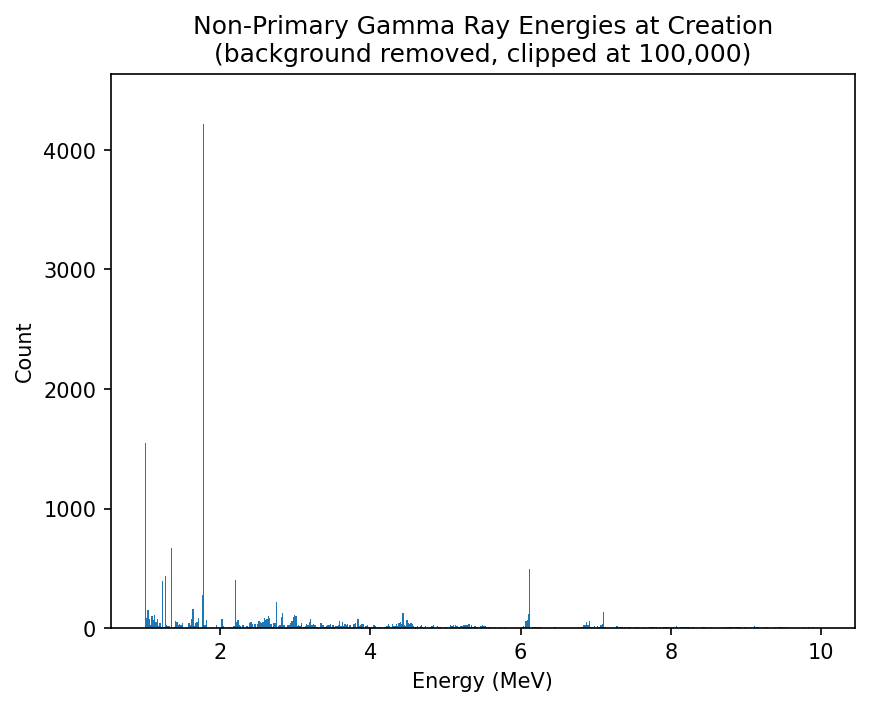

In [186]:
energies = df[wide_e_range & upward]["E"]
plot_with_peaks(
    energies,
    512,
    30000.0,
    xlabel="Energy (MeV)",
    title="Non-Primary Gamma Ray Energies at Creation\n(background removed, clipped at 100,000)",
    savgol_window=101,
    savgol_strength=0.8,
    clip_counts=100_000,
)

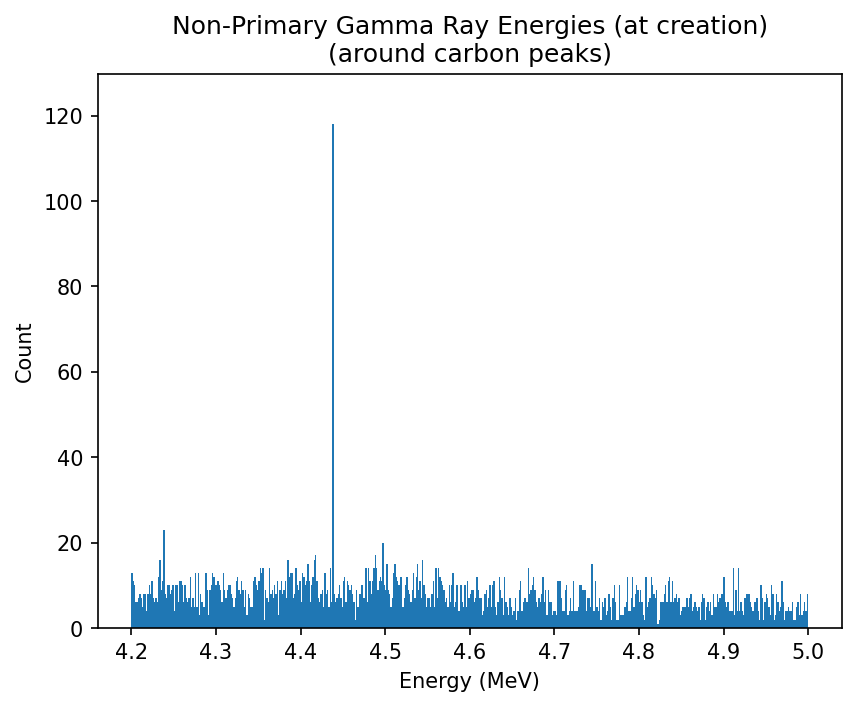

In [187]:
energies = df[carbon_e_range & upward]["E"]
plot_with_peaks(
    energies,
    512,
    200.0,
    clip_counts=3500,
    xlabel="Energy (MeV)",
    title="Non-Primary Gamma Ray Energies (at creation)\n(around carbon peaks)",
)

/var/folders/5j/qsd63dfs2pdfpfcy7c85d27w0000gn/T/ipykernel_91331/1904771352.py:51: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, max(counts) * 1.1)


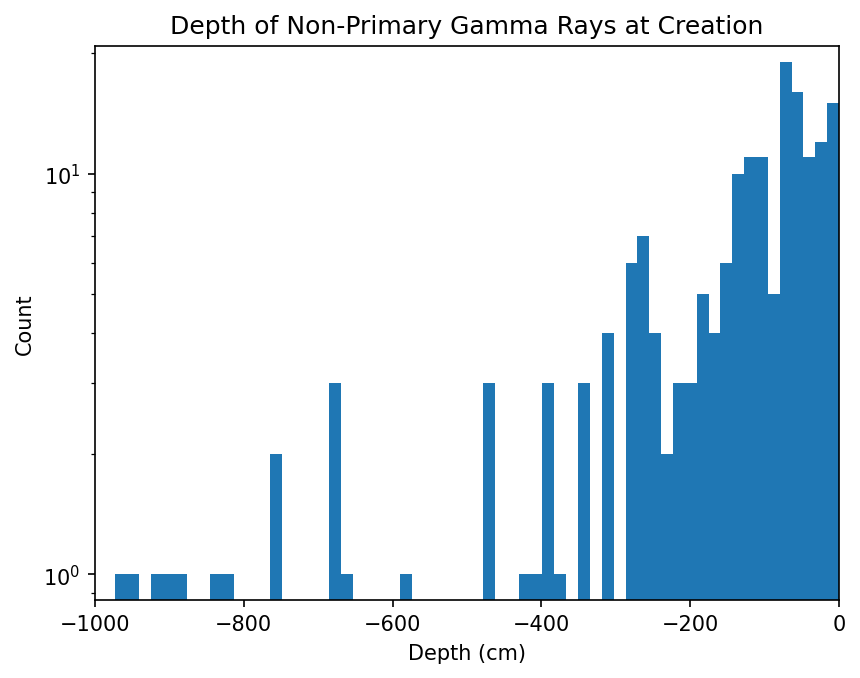

In [188]:
plt.yscale("log")
mctaggart = df["creator"].isin(["nCapture", "RadioactiveDecay", "neutronInelastic"])
plot_with_peaks(
    df[mctaggart & carbon_e_zoom]["z"] / 10,
    256,
    xlabel="Depth (cm)",
    title="Depth of Non-Primary Gamma Rays at Creation",
    xlims=(-1000, 0),
)

In [189]:
print(
    f"z mean: {-np.mean(df[mctaggart & carbon_e_zoom]['z'])/10:.01f} cm, z median: {-np.median(df[mctaggart & carbon_e_zoom]['z'])/10:.01f}"
)

z mean: 347.0 cm, z median: 124.9


In [190]:
df[df["creator"] == "eBrem"]["E"].aggregate(["mean", "std"])

mean     1.874763
std     39.945809
Name: E, dtype: float64

In [191]:
process_name, process_count = np.unique(df["creator"], return_counts=True)

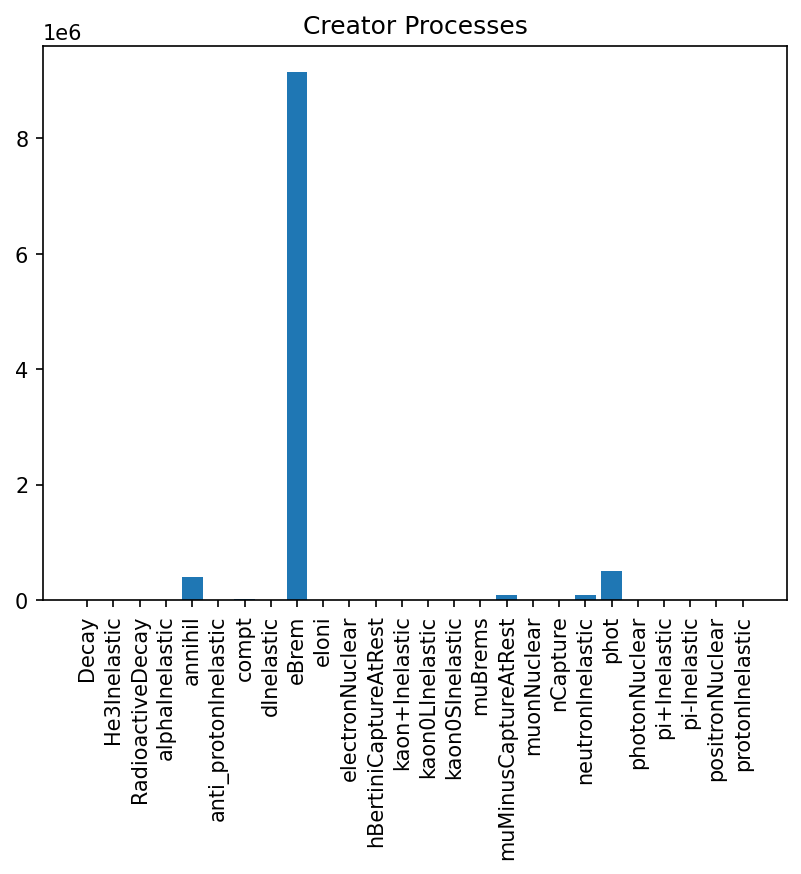

In [192]:
plt.bar(process_name, process_count)
plt.xticks(rotation="vertical")
plt.title("Creator Processes")
plt.show()

/var/folders/5j/qsd63dfs2pdfpfcy7c85d27w0000gn/T/ipykernel_91331/1904771352.py:51: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, max(counts) * 1.1)


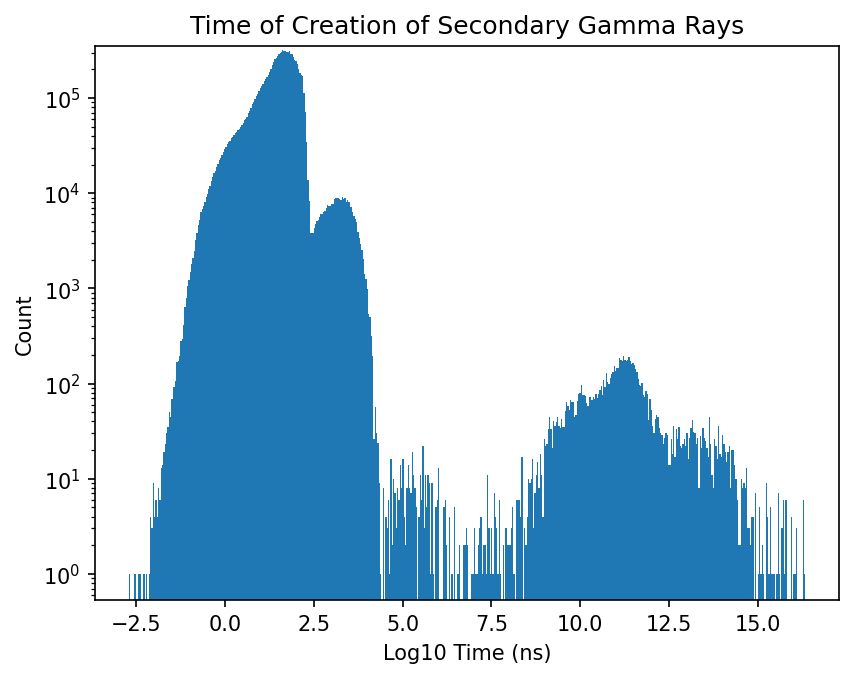

In [193]:
plt.yscale("log")
plot_with_peaks(
    np.log10(df["time"]),
    512,
    title="Time of Creation of Secondary Gamma Rays",
    xlabel="Log10 Time (ns)",
)

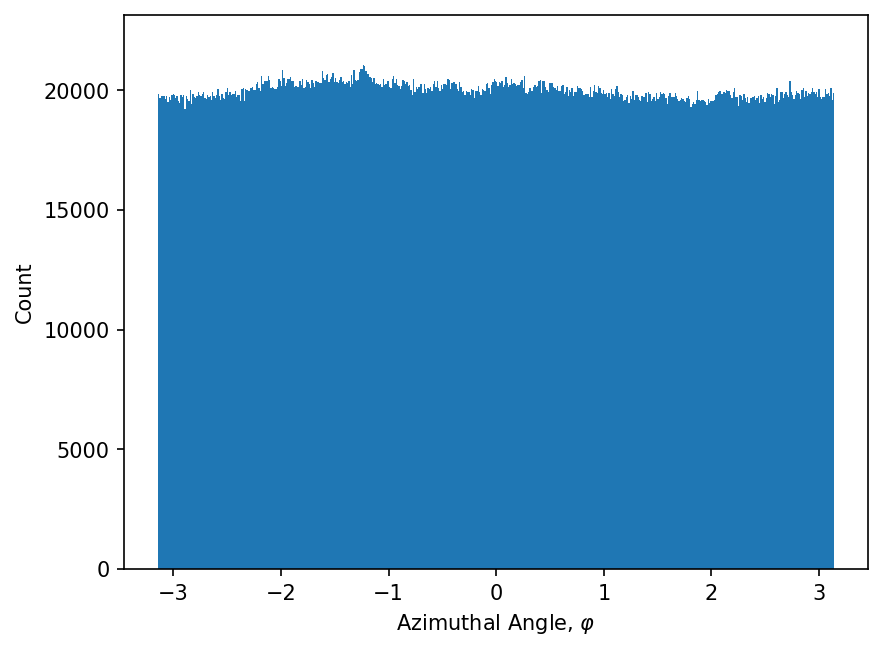

In [194]:
phi = np.atan2(df["p_x"], df["p_y"])
plot_with_peaks(phi, 512, xlabel="Azimuthal Angle, $\\varphi$")

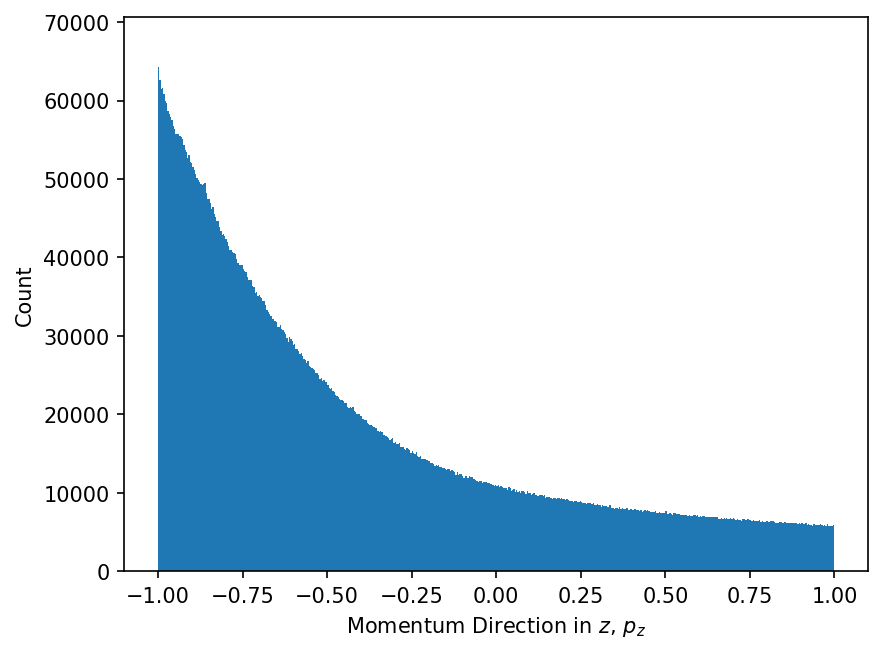

In [195]:
plot_with_peaks(
    df[df["creator"] == "eBrem"]["p_z"], 512, xlabel="Momentum Direction in $z$, $p_z$"
)

# ROOT

In [ ]:
file = uproot.open("archive/run_1_000_000_all_secondaries.root")
print(f"Trees: {file.keys()}")
data = file[file.keys()[0]]


def load(key):
    return np.concat(data[key].array(library="np"))  # type: ignore


print("Keys:", ", ".join(data.keys()))

Trees: ['Results;1']
Keys: KE, MomDirX, MomDirY, MomDirZ, PosX, PosY, PosZ, Time, Name, TrackID


In [4]:
# energy = load("KE")
# pos_z = load("PosZ")
name = load("Name")

(array([968.,  73., 102.,  59.,  49.,  37.,   5.,  13.,   2.,   7.]),
 array([ 0. ,  2.2,  4.4,  6.6,  8.8, 11. , 13.2, 15.4, 17.6, 19.8, 22. ]),
 <BarContainer object of 10 artists>)

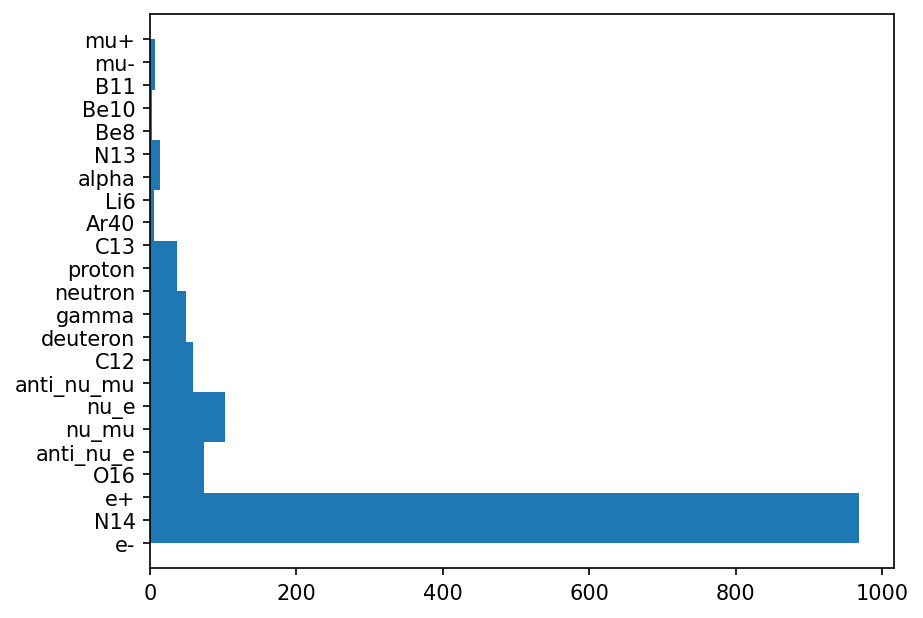

In [ ]:
plt.hist(name, orientation="horizontal")

In [7]:
full_energy_spectrum = (0.04 < energy) & (energy < 7)
carbon_silicon_spectrum = (4.4 < energy) & (energy < 4.5)
hydrogen_peak = (2.2 < energy) & (energy < 2.3)
low_energy_spectrum = (1 < energy) & (energy < 3)

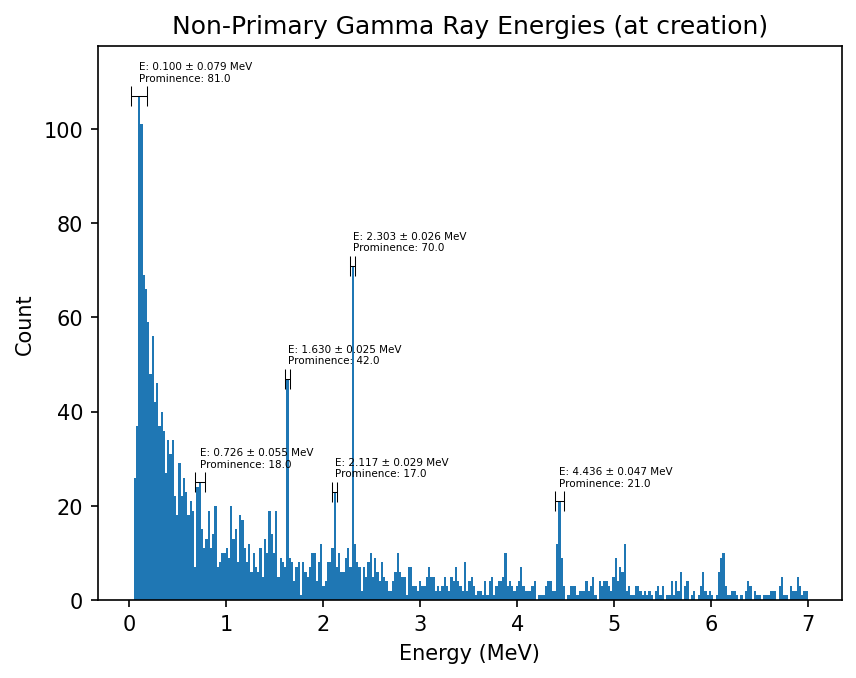

In [11]:
plot_with_peaks(energy[full_energy_spectrum], 300, 15)

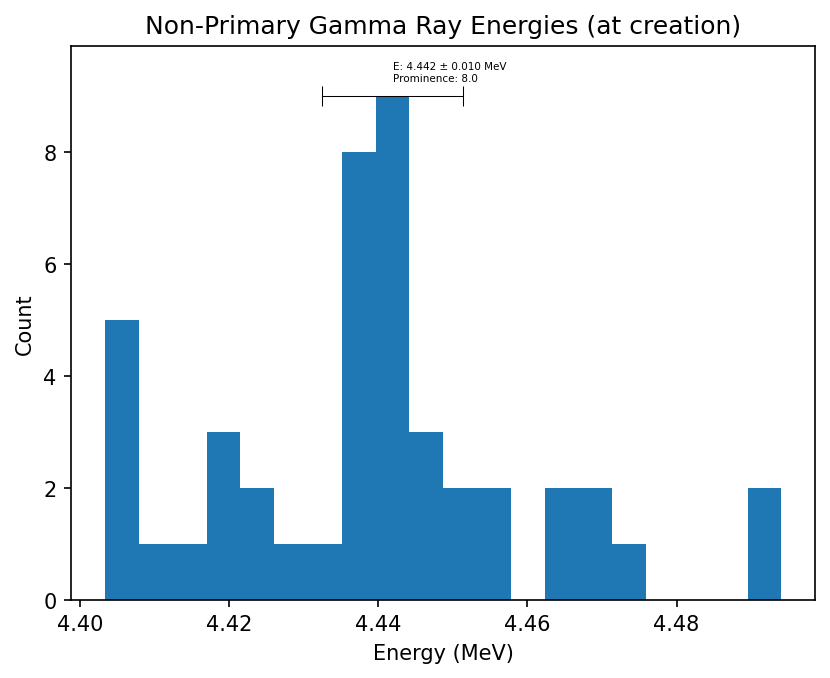

In [12]:
plot_with_peaks(energy[carbon_silicon_spectrum], 20, 4)

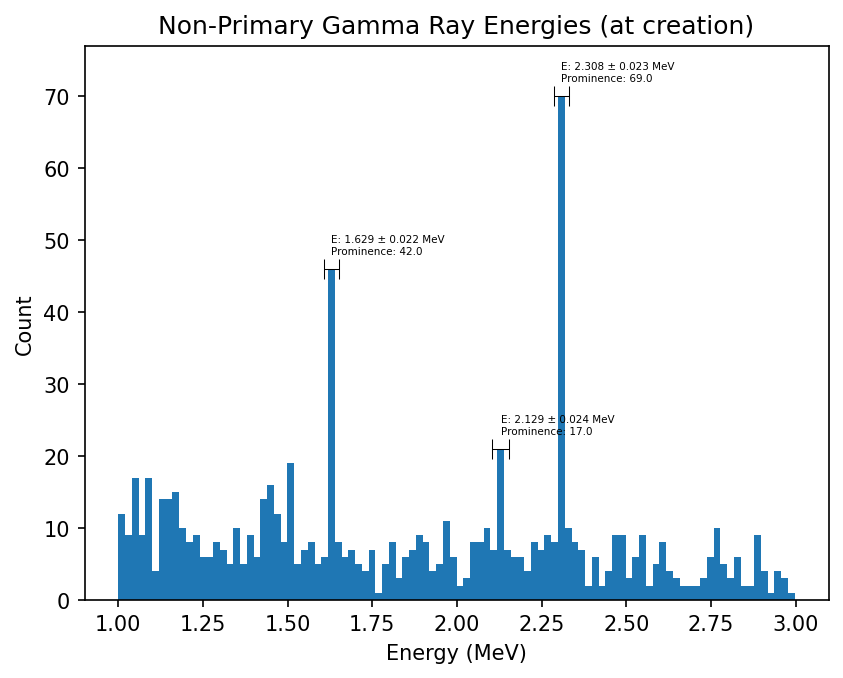

In [96]:
plot_with_peaks(energy[low_energy_spectrum], 100, 15)

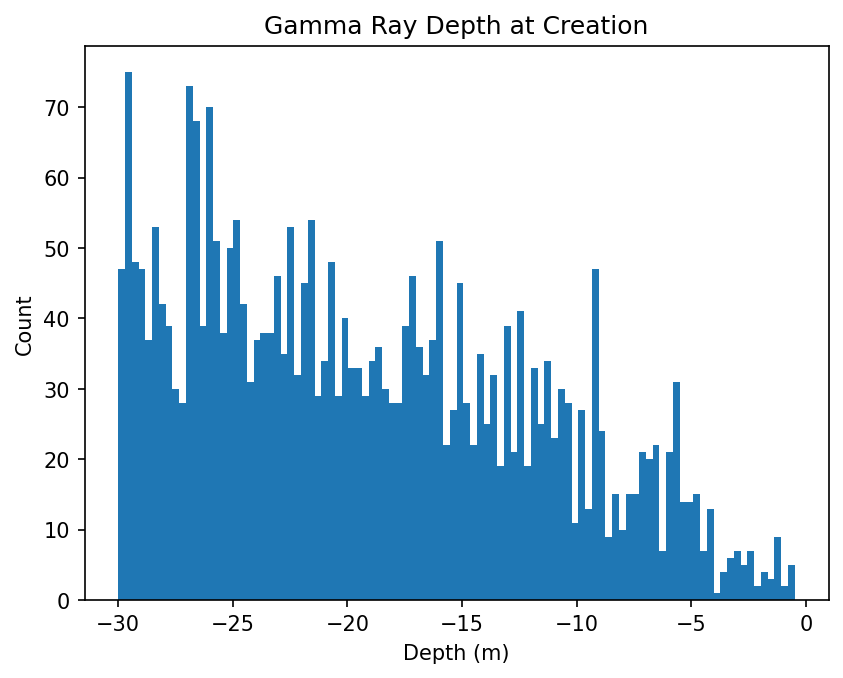

In [ ]:
plt.hist(pos_z / 1000, bins=100)
plt.xlabel("Depth (m)")
plt.ylabel("Count")
plt.title("Gamma Ray Depth at Creation")
plt.show()

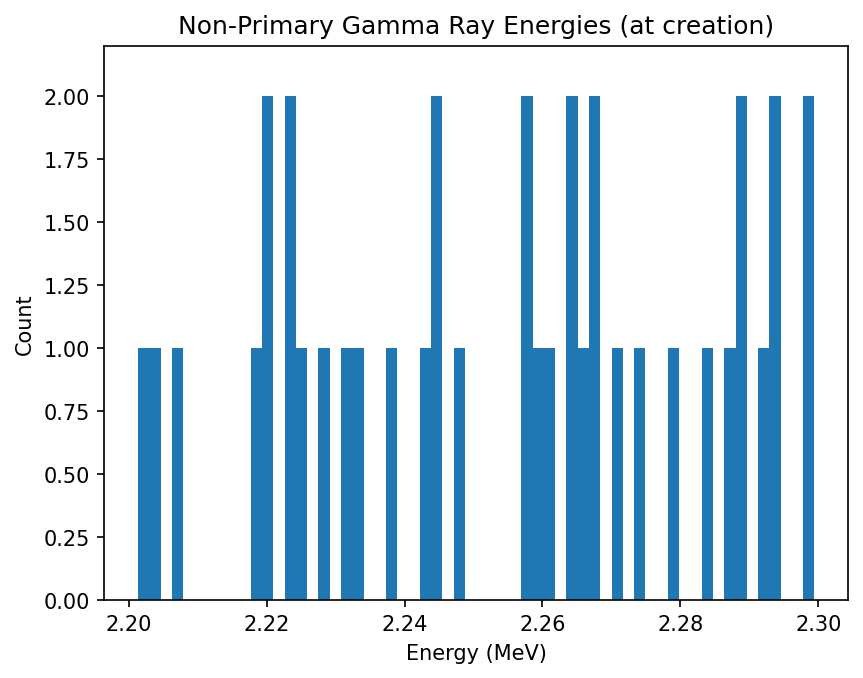

In [108]:
plot_with_peaks(energy[hydrogen_peak], 60, 10)